# ScoNet

This notebook implements the ScoNet architecture in plain PyTorch and is checked against the paper *Gait Patterns as Biomarkers: A Video-Based Approach for Classifying Scoliosis* and the current [OpenGait `sconet.py`](https://github.com/ShiqiYu/OpenGait/blob/master/opengait/modeling/models/sconet.py) / [configuration](https://github.com/ShiqiYu/OpenGait/blob/master/configs/sconet/sconet_scoliosis1k.yaml).

## 1. Imports and experiment settings

In [1]:
import json
import pickle
import random
import time
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ---------- Paths: edit these for your computer ----------
DATASET_ROOT = Path(
    r"C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl"
)
PARTITION_JSON = Path(
    r"C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K\Scoliosis1K_118.json"
)

# ---------- Reproduction controls ----------
RUN_SANITY_CHECK = False  # small, optional end-to-end smoke test
RUN_FULL = True          # set True only after checking the printed split counts
MODEL_VARIANT = "ScoNet"  # "ScoNet" (paper-text CE-only) or "ScoNet-MT" (current official YAML objective)
PROFILE = "quick"             # "quick", "scaled", or "paper"
ONE_PER_CLASS = True         # must remain False for a real experiment

# ---------- Data / architecture (OpenGait YAML) ----------
LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
NUM_CLASSES = 3
IMAGE_HEIGHT = 64
RAW_IMAGE_WIDTH = 64
INPUT_WIDTH = 44   # after cutting 10 px from each side of a 64 px-wide silhouette
N_FRAMES = 30
FULL_EVAL_FRAMES = 720
CHANNELS = (64, 128, 256, 512)
LAYERS = (1, 1, 1, 1)
STRIDES = (1, 2, 2, 1)
MAXPOOL = False
NUM_PARTS = 16
EMBED_DIM = 256

# ---------- Losses ----------
CE_SCALE = 16
LABEL_SMOOTHING = 0.1
TRIPLET_MARGIN = 0.2
CE_LOSS_WEIGHT = 1.0
TRIPLET_LOSS_WEIGHT = 1.0

# ---------- Optimisation ----------
BASE_LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
LR_GAMMA = 0.1
PAPER_MILESTONES = (10_000, 14_000, 18_000)
USE_AMP = torch.cuda.is_available()   # YAML: enable_float16=true
LOG_EVERY = 100                       # YAML: log_iter=100
SAVE_EVERY = 500                      # recovery checkpoints; official YAML saves at 20,000
RESUME = False
MONITOR_DURING_TRAINING = False        # optional; evaluation does not affect gradients
MONITOR_EVERY = 5_000                  # only used when MONITOR_DURING_TRAINING=True
MONITOR_PER_CLASS = 30

PROFILES = {
    "quick":  {"iterations": 200,    "identities": 4, "sequences_per_identity": 4},
    "scaled": {"iterations": 2000,  "identities": 8, "sequences_per_identity": 4},
    "paper":  {"iterations": 20000, "identities": 8, "sequences_per_identity": 8},
}
if PROFILE not in PROFILES:
    raise ValueError(f"Unknown PROFILE {PROFILE!r}; choose from {list(PROFILES)}")

TOTAL_ITERS = PROFILES[PROFILE]["iterations"]
IDENTITIES_PER_BATCH = PROFILES[PROFILE]["identities"]
SEQUENCES_PER_IDENTITY = PROFILES[PROFILE]["sequences_per_identity"]
LR_MILESTONES = tuple(int(TOTAL_ITERS * f) for f in (0.5, 0.7, 0.9))

TRIPLET_MODE = {
    "ScoNet": None,          # paper-text plain ScoNet: CE only
    "ScoNet-MT": "identity", # official YAML: CE + triplet on subject/person IDs
}
if MODEL_VARIANT not in TRIPLET_MODE:
    raise ValueError(f"Unknown MODEL_VARIANT {MODEL_VARIANT!r}; choose from {list(TRIPLET_MODE)}")

SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Paper reference counts are ordered (positive, neutral, negative).
PAPER_SPLITS = {
    "112": (186, 186, 373),
    "114": (124, 124, 497),
    "118": (74, 74, 596),
    "1116": (41, 41, 663),
}
PAPER_ACCURACY = {
    "112": {"ScoNet": 91.4, "ScoNet-MT": 95.2},
    "114": {"ScoNet": 88.6, "ScoNet-MT": 90.5},
    "118": {"ScoNet": 51.3, "ScoNet-MT": 82.0},
    "1116": {"ScoNet": 23.7, "ScoNet-MT": 49.5},
}
PAPER_TABLE2 = {
    "ScoNet": (51.3, 100.0, 33.2),
    "ScoNet-MT": (82.0, 99.0, 76.5),
}
# Paper reference metrics are printed separately from measured run metrics.

SPLIT_KEY = PARTITION_JSON.stem.split("_")[-1]
CONFIG_TAG = (
    f"{MODEL_VARIANT}|{PARTITION_JSON.name}|{PROFILE}|toy={ONE_PER_CLASS}|"
    f"seed={SEED}|frames={N_FRAMES}|batch={IDENTITIES_PER_BATCH}x{SEQUENCES_PER_IDENTITY}|"
    f"channels={CHANNELS}|layers={LAYERS}|strides={STRIDES}|parts={NUM_PARTS}|embed={EMBED_DIM}|"
    f"lr={BASE_LR}|momentum={MOMENTUM}|weight_decay={WEIGHT_DECAY}|gamma={LR_GAMMA}|"
    f"milestones={LR_MILESTONES}|margin={TRIPLET_MARGIN}|ce_scale={CE_SCALE}|"
    f"ce_weight={CE_LOSS_WEIGHT}|triplet_weight={TRIPLET_LOSS_WEIGHT}|"
    f"label_smoothing={LABEL_SMOOTHING}"
)

print(f"Device: {DEVICE} | PyTorch {torch.__version__}")
print(f"Dataset root exists: {DATASET_ROOT.is_dir()} -> {DATASET_ROOT}")
print(f"Partition file exists: {PARTITION_JSON.is_file()} -> {PARTITION_JSON}")
print(f"Model objective: {MODEL_VARIANT} | {TOTAL_ITERS:,} iterations | "
      f"{IDENTITIES_PER_BATCH} identities x {SEQUENCES_PER_IDENTITY} sequences")
print(f"LR milestones for this profile: {LR_MILESTONES}")
if PROFILE == "paper":
    print(f"Paper YAML milestones: {PAPER_MILESTONES}")

Device: cuda | PyTorch 2.6.0+cu124
Dataset root exists: True -> C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl
Partition file exists: True -> C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K\Scoliosis1K_118.json
Model objective: ScoNet | 200 iterations | 4 identities x 4 sequences
LR milestones for this profile: (100, 140, 180)


## 2. Load and inspect silhouette PKLs

In [2]:
def load_pkl(path):
    """Read one silhouette sequence as [frames, height, width]."""
    with open(path, "rb") as file:
        sequence = np.asarray(pickle.load(file))

    if sequence.ndim == 4 and sequence.shape[1] == 1:      # [T, 1, H, W]
        sequence = sequence[:, 0]
    elif sequence.ndim == 4 and sequence.shape[-1] == 1:   # [T, H, W, 1]
        sequence = sequence[..., 0]

    if sequence.ndim != 3 or sequence.shape[0] == 0:
        raise ValueError(f"Expected non-empty [T,H,W], got {sequence.shape} from {path}")
    if sequence.shape[1:] != (IMAGE_HEIGHT, RAW_IMAGE_WIDTH):
        raise ValueError(
            f"Expected each raw frame to be {(IMAGE_HEIGHT, RAW_IMAGE_WIDTH)}, "
            f"got {sequence.shape[1:]} from {path}"
        )
    if sequence.min() < 0 or sequence.max() > 255:
        raise ValueError(f"Silhouette values must be in 0..255, got {sequence.min()}..{sequence.max()} in {path}")
    return sequence


def class_from_path(path, root):
    """Infer the diagnostic class from a parent directory name."""
    for folder_name in path.relative_to(root).parts[:-1]:
        label = folder_name.lower()
        if label in LABEL_TO_ID:
            return LABEL_TO_ID[label]
    return None


def find_one_sample_per_class(root):
    found = {}
    for path in sorted(root.rglob("*.pkl")):
        class_id = class_from_path(path, root)
        if class_id is not None:
            found.setdefault(LABELS[class_id], path)
        if len(found) == NUM_CLASSES:
            break
    return found


sample_paths = {}
raw_samples = {}
if DATASET_ROOT.is_dir():
    sample_paths = find_one_sample_per_class(DATASET_ROOT)
    missing_labels = [label for label in LABELS if label not in sample_paths]
    if missing_labels:
        print(f"Could not find a PKL for: {missing_labels}. Check the folder names and DATASET_ROOT.")
    else:
        for label in LABELS:
            raw_samples[label] = load_pkl(sample_paths[label])
            sequence = raw_samples[label]
            print(f"{label:9s} | {sample_paths[label].relative_to(DATASET_ROOT)} | "
                  f"shape={sequence.shape} dtype={sequence.dtype} range={sequence.min()}..{sequence.max()}")
else:
    print("Dataset root is not available in this environment. Edit DATASET_ROOT before data inspection/training.")

negative  | 00493\negative\000_180\000_180.pkl | shape=(300, 64, 64) dtype=uint8 range=0..255
neutral   | 01293\neutral\000_180\000_180.pkl | shape=(300, 64, 64) dtype=uint8 range=0..255
positive  | 00000\positive\000_180\000_180.pkl | shape=(300, 64, 64) dtype=uint8 range=0..255


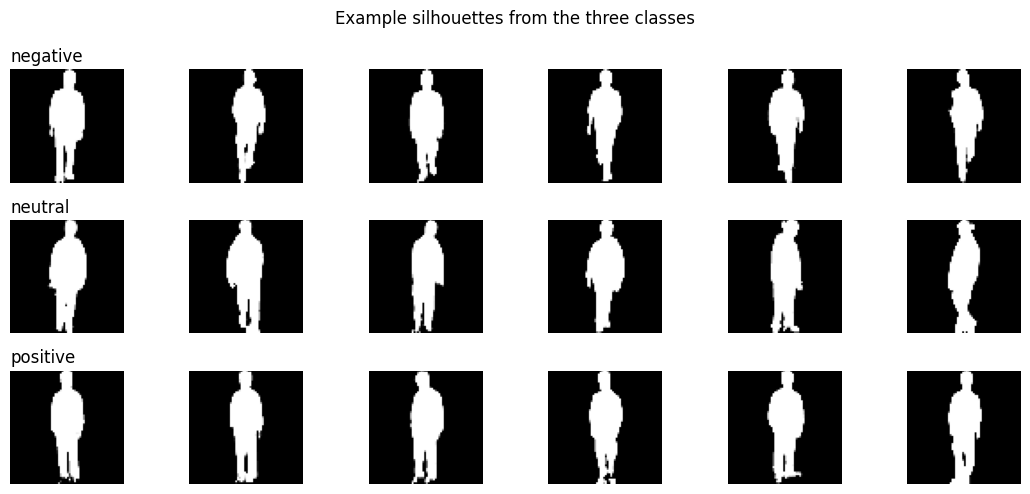

In [3]:
if len(raw_samples) == NUM_CLASSES:
    fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 5))
    for row, label in enumerate(LABELS):
        sequence = raw_samples[label]
        frame_ids = np.linspace(0, len(sequence) - 1, 6).round().astype(int)
        for col, frame_id in enumerate(frame_ids):
            axes[row, col].imshow(sequence[frame_id], cmap="gray")
            axes[row, col].axis("off")
        axes[row, 0].set_title(label, loc="left")
    fig.suptitle("Example silhouettes from the three classes")
    plt.tight_layout()
    plt.show()
else:
    print("Sample preview skipped because one or more class samples were not found.")

## 3. Preprocessing

In [4]:
def cut_and_normalize(sequence):
    """Raw [T,64,64] uint8-like silhouette -> float32 [T,64,44] in 0..1."""
    cut = int(sequence.shape[-1] // 64) * 10
    if cut:
        sequence = sequence[..., cut:-cut]
    return sequence.astype(np.float32) / 255.0


def random_clip(sequence, n_frames=N_FRAMES):
    """Sample frames without replacement unless the sequence is shorter than n_frames."""
    frame_ids = np.random.choice(
        len(sequence), size=n_frames, replace=(len(sequence) < n_frames)
    )
    return sequence[frame_ids]


def training_clip(sequence, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(sequence, n_frames))


if raw_samples:
    example_clip = training_clip(raw_samples["positive"])
    assert example_clip.shape == (N_FRAMES, IMAGE_HEIGHT, INPUT_WIDTH)
    print("Training clip:", example_clip.shape, "| range:", example_clip.min(), "..", example_clip.max())

Training clip: (30, 64, 44) | range: 0.0 .. 1.0


## 4. ScoNet architecture


In [5]:
class BasicBlock(nn.Module):
    """Two 3x3 convolutions with a residual connection, matching torchvision BasicBlock."""
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.downsample = nn.Identity()

    def forward(self, x):
        identity = self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class ResNet9(nn.Module):
    """OpenGait ResNet9 configuration for 1-channel 64x44 silhouettes."""
    def __init__(self, in_channels=1, channels=CHANNELS, layers=LAYERS, strides=STRIDES, maxpool=MAXPOOL):
        super().__init__()
        if not (len(channels) == len(layers) == len(strides) == 4):
            raise ValueError("ResNet9 expects four stage definitions.")

        self.conv1 = nn.Conv2d(in_channels, channels[0], 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels[0])
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.use_maxpool = maxpool

        blocks = []
        in_ch = channels[0]
        for out_ch, n_blocks, stride in zip(channels, layers, strides):
            if n_blocks < 1:
                raise ValueError("Every ResNet9 stage must contain at least one block.")
            blocks.append(BasicBlock(in_ch, out_ch, stride=stride))
            in_ch = out_ch
            for _ in range(1, n_blocks):
                blocks.append(BasicBlock(in_ch, out_ch, stride=1))
        self.stages = nn.Sequential(*blocks)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        if self.use_maxpool:
            x = self.maxpool(x)
        return self.stages(x)


class FrameWise(nn.Module):
    """Apply the same 2D backbone to each frame independently."""
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        # [N, C, T, H, W] -> [N*T, C, H, W]
        n, c, t, h, w = x.shape
        frames = x.permute(0, 2, 1, 3, 4).reshape(n * t, c, h, w)
        features = self.backbone(frames)
        _, out_c, out_h, out_w = features.shape
        return features.reshape(n, t, out_c, out_h, out_w).permute(0, 2, 1, 3, 4).contiguous()


class HorizontalPooling(nn.Module):
    """HPP with one bin per feature-map row: mean pooling + max pooling."""
    def __init__(self, num_parts=NUM_PARTS):
        super().__init__()
        self.num_parts = num_parts

    def forward(self, x):
        # [N,C,H,W] -> [N,C,parts, pixels_per_part]
        n, c, h, w = x.shape
        if h % self.num_parts != 0:
            raise ValueError(f"Feature-map height {h} must be divisible by {self.num_parts} parts.")
        x = x.reshape(n, c, self.num_parts, -1)
        return x.mean(dim=-1) + x.max(dim=-1).values


class SeparateFCs(nn.Module):
    """Independent 512->256 fully connected projection for each horizontal part."""
    def __init__(self, parts=NUM_PARTS, in_channels=CHANNELS[-1], out_channels=EMBED_DIM):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(parts, in_channels, out_channels))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        # [N,C,P] -> [P,N,C] -> per-part projection -> [N,C_out,P]
        x = x.permute(2, 0, 1).contiguous()
        return x.matmul(self.weight).permute(1, 2, 0).contiguous()


class SeparateBNNecks(nn.Module):
    """BatchNorm followed by an independent cosine classifier for each part."""
    def __init__(self, parts=NUM_PARTS, in_channels=EMBED_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.bn = nn.BatchNorm1d(in_channels * parts)  # OpenGait parallel_BN1d=True
        self.weight = nn.Parameter(torch.empty(parts, in_channels, num_classes))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        n, c, p = x.shape
        x = self.bn(x.reshape(n, c * p)).reshape(n, c, p)
        part_features = F.normalize(x.permute(2, 0, 1).contiguous(), dim=-1)
        class_weights = F.normalize(self.weight, dim=1)
        logits = part_features.matmul(class_weights)
        return x, logits.permute(1, 2, 0).contiguous()


class ScoNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = FrameWise(ResNet9())
        self.temporal_pool = torch.amax
        self.hpp = HorizontalPooling(NUM_PARTS)
        self.fcs = SeparateFCs()
        self.bn_necks = SeparateBNNecks()

    def forward(self, silhouettes):
        # Input: [N,T,64,44]
        x = silhouettes.unsqueeze(1)                 # [N,1,T,H,W]
        x = self.backbone(x)                          # [N,512,T,16,11]
        x = self.temporal_pool(x, dim=2)              # [N,512,16,11]
        x = self.hpp(x)                               # [N,512,16]
        embedding = self.fcs(x)                       # [N,256,16]
        _, logits = self.bn_necks(embedding)          # [N,3,16]
        return embedding, logits


def init_weights(module):
    """Same initialization policy as OpenGait BaseModel.init_parameters()."""
    if isinstance(module, nn.Conv2d):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        if module.affine:
            nn.init.normal_(module.weight, 1.0, 0.02)
            nn.init.zeros_(module.bias)


def make_model():
    model = ScoNet()
    model.apply(init_weights)
    return model.to(DEVICE)

In [6]:
# One shape / backward smoke test (no dataset required).
set_seed()
shape_test_model = make_model()
test_input = torch.rand(2, N_FRAMES, IMAGE_HEIGHT, INPUT_WIDTH, device=DEVICE)
with torch.no_grad():
    test_embedding, test_logits = shape_test_model.eval()(test_input)

print("Embedding shape:", tuple(test_embedding.shape), "expected:", (2, EMBED_DIM, NUM_PARTS))
print("Logits shape:   ", tuple(test_logits.shape), "expected:", (2, NUM_CLASSES, NUM_PARTS))
print(f"Parameters: {sum(p.numel() for p in shape_test_model.parameters()):,}")
assert test_embedding.shape == (2, EMBED_DIM, NUM_PARTS)
assert test_logits.shape == (2, NUM_CLASSES, NUM_PARTS)
del shape_test_model, test_input, test_embedding, test_logits

Embedding shape: (2, 256, 16) expected: (2, 256, 16)
Logits shape:    (2, 3, 16) expected: (2, 3, 16)
Parameters: 7,014,592


## 5. Losses

In [7]:
def pairwise_distance(embeddings):
    """Pairwise Euclidean distances: [P,N,C] -> [P,N,N]."""
    squared_norm = (embeddings ** 2).sum(dim=-1)
    distance_squared = (
        squared_norm.unsqueeze(2)
        + squared_norm.unsqueeze(1)
        - 2 * embeddings.matmul(embeddings.transpose(1, 2))
    )
    return torch.sqrt(F.relu(distance_squared))


def triplet_loss(embeddings, labels, margin=TRIPLET_MARGIN):
    """OpenGait-style all-pairs triplet loss, returning a scalar averaged over parts."""
    labels = labels.reshape(-1)
    if torch.unique(labels).numel() < 2:
        raise ValueError("Triplet loss needs at least two distinct triplet labels in a batch.")

    # [N,C,P] -> [P,N,C], matching OpenGait's TripletLoss.
    x = embeddings.permute(2, 0, 1).contiguous().float()
    distances = pairwise_distance(x)
    same_label = labels.unsqueeze(1).eq(labels.unsqueeze(0))
    different_label = ~same_label

    n_parts, batch_size, _ = distances.shape
    ap_dist = distances[:, same_label].view(n_parts, batch_size, -1, 1)
    an_dist = distances[:, different_label].view(n_parts, batch_size, 1, -1)
    losses = F.relu(ap_dist - an_dist + margin).reshape(n_parts, -1)

    active = (losses != 0).sum(dim=-1).float()
    part_loss = losses.sum(dim=-1) / (active + 1e-9)
    part_loss[active == 0] = 0
    return part_loss.mean()


def cross_entropy_loss(logits, class_ids):
    """OpenGait CrossEntropyLoss: logits [N,classes,P], scale=16, label smoothing=0.1."""
    n, _, parts = logits.shape
    targets = class_ids.reshape(n, 1).expand(n, parts)
    return F.cross_entropy(
        logits.float() * CE_SCALE,
        targets,
        label_smoothing=LABEL_SMOOTHING,
    )


def compute_loss(embedding, logits, subject_ids, class_ids, triplet_mode):
    ce = cross_entropy_loss(logits, class_ids) * CE_LOSS_WEIGHT
    if triplet_mode is None:
        triplet = ce.new_zeros(())
    elif triplet_mode == "identity":
        triplet = triplet_loss(embedding, subject_ids) * TRIPLET_LOSS_WEIGHT
    else:
        raise ValueError(f"Unknown triplet mode: {triplet_mode}")
    return ce + triplet, ce, triplet


# Unit test for both losses and gradients.
test_embeddings = torch.randn(6, EMBED_DIM, NUM_PARTS, device=DEVICE, requires_grad=True)
test_logits = torch.randn(6, NUM_CLASSES, NUM_PARTS, device=DEVICE, requires_grad=True)
test_ids = torch.tensor([0, 0, 1, 1, 2, 2], device=DEVICE)
test_classes = torch.tensor([0, 0, 1, 1, 2, 2], device=DEVICE)
test_total, test_ce, test_triplet = compute_loss(
    test_embeddings, test_logits, test_ids, test_classes, "identity"
)
test_total.backward()
print(f"Loss smoke test — total: {test_total.item():.4f}, CE: {test_ce.item():.4f}, triplet: {test_triplet.item():.4f}")
assert torch.isfinite(test_total) and test_embeddings.grad is not None and test_logits.grad is not None
del test_embeddings, test_logits, test_ids, test_classes, test_total, test_ce, test_triplet

Loss smoke test — total: 13.2369, CE: 12.2374, triplet: 0.9995


## 6. Batch construction

In [8]:
def load_partition(path):
    if not path.is_file():
        raise FileNotFoundError(f"Partition JSON not found: {path}. Edit PARTITION_JSON first.")
    with open(path, "r", encoding="utf-8") as file:
        partition = json.load(file)
    if "TRAIN_SET" not in partition or "TEST_SET" not in partition:
        raise KeyError("Partition JSON must contain TRAIN_SET and TEST_SET.")
    return partition


def build_index(root, subject_ids):
    """Return (subject_id, class_id, PKL path) entries for a partition."""
    if not root.is_dir():
        raise FileNotFoundError(f"Dataset root not found: {root}")

    items = []
    missing_subjects = []
    for subject_id in subject_ids:
        subject_folder = root / str(subject_id)
        if not subject_folder.is_dir():
            missing_subjects.append(str(subject_id))
            continue

        for path in sorted(subject_folder.rglob("*.pkl")):
            class_id = class_from_path(path, root)
            if class_id is not None:
                items.append((str(subject_id), class_id, path))

    print(f"Indexed {len(items)} sequences from {len({x[0] for x in items})} subjects.")
    if missing_subjects:
        print(f"Warning: {len(missing_subjects)} partition subjects have no folder, e.g. {missing_subjects[:8]}")
    if not items:
        raise RuntimeError(
            "No sequences were indexed. Check DATASET_ROOT, subject-folder names, and class folder names."
        )
    return items


def class_counts(items):
    counts = {label: 0 for label in LABELS}
    for _, class_id, _ in items:
        counts[LABELS[class_id]] += 1
    return counts


def check_split(train_items, test_items, partition):
    train_subjects = {str(sid) for sid in partition["TRAIN_SET"]}
    test_subjects = {str(sid) for sid in partition["TEST_SET"]}
    overlap = train_subjects & test_subjects
    if overlap:
        raise ValueError(f"TRAIN_SET and TEST_SET share {len(overlap)} subject IDs, e.g. {sorted(overlap)[:8]}")

    train_counts = class_counts(train_items)
    test_counts = class_counts(test_items)
    print("Train class counts:", train_counts)
    print("Test class counts: ", test_counts)

    if SPLIT_KEY in PAPER_SPLITS:
        pos, neu, neg = PAPER_SPLITS[SPLIT_KEY]
        print(f"Paper-reported train counts for split {SPLIT_KEY} (positive, neutral, negative): "
              f"{pos}, {neu}, {neg}")
        observed_paper_order = (
            train_counts["positive"], train_counts["neutral"], train_counts["negative"]
        )
        if observed_paper_order != (pos, neu, neg):
            print("WARNING: indexed counts do not match the paper reference. Check split file and folder layout.")
        if pos + neu + neg == 744 and SPLIT_KEY == "118":
            print("Note: the paper lists 745 training sequences in text but 74+74+596=744 in its class counts.")

    return train_counts, test_counts


def make_triplet_batch_fn(items, identities_per_batch, sequences_per_identity):
    """Generate (clips, local subject IDs, diagnostic class IDs) for one optimizer iteration."""
    by_subject = {}
    for subject_id, class_id, path in items:
        by_subject.setdefault(subject_id, []).append((class_id, path))

    subjects = list(by_subject)
    if len(subjects) < 2:
        raise ValueError("At least two subjects are required for identity triplet training.")
    subject_to_label = {subject_id: index for index, subject_id in enumerate(subjects)}

    def get_batch():
        chosen_subjects = random.sample(subjects, min(identities_per_batch, len(subjects)))
        clips, subject_labels, class_labels = [], [], []

        for subject_id in chosen_subjects:
            pool = by_subject[subject_id]
            if len(pool) >= sequences_per_identity:
                chosen = random.sample(pool, sequences_per_identity)
            else:
                chosen = random.choices(pool, k=sequences_per_identity)

            for class_id, path in chosen:
                clips.append(training_clip(load_pkl_cached(path)))
                subject_labels.append(subject_to_label[subject_id])
                class_labels.append(class_id)

        return (
            np.stack(clips).astype(np.float32),
            np.asarray(subject_labels, dtype=np.int64),
            np.asarray(class_labels, dtype=np.int64),
        )

    return get_batch


@lru_cache(maxsize=128)
def load_pkl_cached(path):
    return load_pkl(path)


def select_one_per_class(items):
    """Diagnostic-only mini-split; never use for the reported paper experiment."""
    selected = {}
    for item in items:
        _, class_id, _ = item
        selected.setdefault(class_id, item)
    if len(selected) != NUM_CLASSES:
        raise ValueError("Cannot select one sample per class: the indexed split is missing a class.")
    return [selected[class_id] for class_id in range(NUM_CLASSES)]


def make_monitor_subset(test_items, per_class=MONITOR_PER_CLASS):
    """Fixed, class-balanced test subset for optional monitoring only."""
    rng = random.Random(SEED)
    subset = []
    for class_id in range(NUM_CLASSES):
        pool = [item for item in test_items if item[1] == class_id]
        if not pool:
            raise ValueError(f"Test split has no samples for class {LABELS[class_id]}.")
        subset.extend(rng.sample(pool, min(per_class, len(pool))))
    return subset

## 7. Training, checkpoints, and curves

In [9]:
def save_checkpoint(path, model, optimizer, scheduler, scaler, iteration, history):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "config_tag": CONFIG_TAG,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "iteration": iteration,
        "history": history,
    }, path)


def load_checkpoint(path, model, optimizer, scheduler, scaler):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    if checkpoint.get("config_tag") != CONFIG_TAG:
        raise ValueError(
            "Checkpoint configuration does not match this run. "
            "Use a new checkpoint file or verify MODEL_VARIANT/PARTITION_JSON/PROFILE."
        )
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    next_iteration = int(checkpoint["iteration"]) + 1
    print(f"Resumed checkpoint at iteration {next_iteration - 1}.")
    return checkpoint["history"], next_iteration


def predict(model, sequence, max_frames=FULL_EVAL_FRAMES):
    """Predict one sequence using OpenGait's mean-over-parts logits rule."""
    model.eval()
    sequence = sequence[:max_frames]
    images = cut_and_normalize(sequence)
    x = torch.as_tensor(images, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    with torch.no_grad():
        _, logits = model(x)                         # [1, 3, 16]
        scores = logits.float().mean(dim=-1)        # [1, 3]
        probabilities = torch.softmax(scores * CE_SCALE, dim=1)[0].cpu().numpy()
    return int(probabilities.argmax()), probabilities


def confusion_matrix_for_items(model, items, max_frames=FULL_EVAL_FRAMES):
    """Confusion matrix rows=true labels, columns=predicted labels."""
    matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for _, true_class, path in items:
        predicted_class, _ = predict(model, load_pkl_cached(path), max_frames)
        matrix[true_class, predicted_class] += 1
    return matrix


def metrics_from_confusion(matrix):
    support = matrix.sum(axis=1)
    predicted_count = matrix.sum(axis=0)
    true_positive = np.diag(matrix)

    precision = true_positive / np.maximum(predicted_count, 1)
    recall = true_positive / np.maximum(support, 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

    total = max(int(matrix.sum()), 1)
    accuracy = float(true_positive.sum() / total)
    macro_precision = float(precision.mean())
    macro_recall = float(recall.mean())
    macro_f1 = float(f1.mean())
    weighted_f1 = float(np.average(f1, weights=support)) if support.sum() else 0.0

    return {
        "accuracy": accuracy,
        "precision_per_class": precision,
        "recall_per_class": recall,
        "f1_per_class": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
    }


def report_metrics(matrix):
    """Print metrics derived from this run's confusion matrix, plus paper references."""
    result = metrics_from_confusion(matrix)
    print("Confusion matrix (rows=true, columns=predicted; order: negative, neutral, positive)")
    print(matrix)
    print(f"\nAccuracy       : {result['accuracy']:.3%}")
    print(f"Macro precision: {result['macro_precision']:.3%}")
    print(f"Macro recall   : {result['macro_recall']:.3%}")
    print(f"Macro F1       : {result['macro_f1']:.3%}")
    print(f"Weighted F1    : {result['weighted_f1']:.3%}")

    print("\nPer-class metrics:")
    for i, label in enumerate(LABELS):
        print(f"  {label:9s} precision={result['precision_per_class'][i]:.3f} "
              f"recall={result['recall_per_class'][i]:.3f} f1={result['f1_per_class'][i]:.3f}")

    # In the paper's three-class setting, positive-class recall is reported as sensitivity,
    # while negative-class recall is reported as specificity. This is an explicit class-wise
    # interpretation; it is not a general multiclass specificity formula.
    positive_recall = result["recall_per_class"][LABEL_TO_ID["positive"]]
    negative_recall = result["recall_per_class"][LABEL_TO_ID["negative"]]
    print(f"\nPaper-style sensitivity (positive-class recall): {positive_recall:.3%}")
    print(f"Paper-style specificity (negative-class recall): {negative_recall:.3%}")

    if MODEL_VARIANT in PAPER_TABLE2:
        ref = PAPER_TABLE2[MODEL_VARIANT]
        print("\nPaper Table 2 reference for this model (accuracy, sensitivity, specificity):")
        print(f"  {MODEL_VARIANT}: {ref[0]:.1f}%, {ref[1]:.1f}%, {ref[2]:.1f}%")
        print("  These are paper-reported references, not values computed from this run. "
              "The paper's metric reporting does not perfectly reconcile with its published "
              "three-class confusion matrix, so compare cautiously.")
    return result


def train(model, get_batch, total_iterations, *, triplet_mode, lr=BASE_LR,
          milestones=LR_MILESTONES, log_every=LOG_EVERY, amp=USE_AMP,
          checkpoint_path=None, save_every=SAVE_EVERY, resume=False,
          monitor_items=None, monitor_every=0):
    amp = bool(amp and DEVICE.type == "cuda")
    optimizer = torch.optim.SGD(
        model.parameters(), lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer, milestones=list(milestones), gamma=LR_GAMMA
    )
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    history = {"total": [], "ce": [], "triplet": [], "train_acc": [],
               "monitor_iter": [], "monitor_acc": [], "monitor_f1": [], "monitor_recall": []}
    start_iteration = 1

    if resume:
        if checkpoint_path is None or not Path(checkpoint_path).is_file():
            print("RESUME=True but no checkpoint was found; starting from iteration 1.")
        else:
            history, start_iteration = load_checkpoint(
                checkpoint_path, model, optimizer, scheduler, scaler
            )

    start_time = time.time()
    for iteration in range(start_iteration, total_iterations + 1):
        model.train()
        batch_images, subject_ids, class_ids = get_batch()
        batch_images = torch.as_tensor(batch_images, dtype=torch.float32, device=DEVICE)
        subject_ids = torch.as_tensor(subject_ids, dtype=torch.long, device=DEVICE)
        class_ids = torch.as_tensor(class_ids, dtype=torch.long, device=DEVICE)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            embeddings, logits = model(batch_images)
        loss, ce, triplet = compute_loss(
            embeddings.float(), logits.float(), subject_ids, class_ids, triplet_mode
        )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        # Sequence-level training accuracy: same average-over-parts rule as inference.
        train_acc = (logits.float().mean(dim=-1).argmax(dim=1) == class_ids).float().mean().item()
        history["total"].append(float(loss.detach().item()))
        history["ce"].append(float(ce.detach().item()))
        history["triplet"].append(float(triplet.detach().item()))
        history["train_acc"].append(train_acc)

        if iteration == start_iteration or iteration % log_every == 0:
            elapsed = time.time() - start_time
            remaining = max(total_iterations - iteration, 0)
            eta_minutes = (elapsed / max(iteration - start_iteration + 1, 1)) * remaining / 60
            print(f"iter {iteration:5d} | total {loss.item():.4f} | CE {ce.item():.4f} | "
                  f"triplet {triplet.item():.4f} | acc {train_acc:.3f} | ETA {eta_minutes:.1f} min")

        if monitor_every and monitor_items and iteration % monitor_every == 0:
            matrix = confusion_matrix_for_items(model, monitor_items)
            monitor_metrics = metrics_from_confusion(matrix)
            history["monitor_iter"].append(iteration)
            history["monitor_acc"].append(monitor_metrics["accuracy"])
            history["monitor_f1"].append(monitor_metrics["macro_f1"])
            history["monitor_recall"].append(monitor_metrics["recall_per_class"].tolist())
            print(f"  monitor subset at {iteration}: accuracy {monitor_metrics['accuracy']:.3f}, "
                  f"macro F1 {monitor_metrics['macro_f1']:.3f}")

        if checkpoint_path and save_every and (iteration % save_every == 0):
            save_checkpoint(path=checkpoint_path, model=model, optimizer=optimizer,
                            scheduler=scheduler, scaler=scaler, iteration=iteration, history=history)

    if checkpoint_path:
        save_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler, total_iterations, history)
    return history


def plot_training_history(history, triplet_mode):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    train_iterations = np.arange(1, len(history["train_acc"]) + 1)

    axes[0].plot(train_iterations, history["total"], label="total loss", linewidth=1.5)
    axes[0].plot(train_iterations, history["ce"], label="cross-entropy", alpha=0.9)
    if triplet_mode is not None:
        axes[0].plot(train_iterations, history["triplet"], label="triplet", alpha=0.9)
    axes[0].set_title("Training losses")
    axes[0].set_xlabel("iteration")
    axes[0].set_ylabel("loss")
    axes[0].legend()

    axes[1].plot(train_iterations, history["train_acc"], alpha=0.25, label="training accuracy")
    if history["monitor_iter"]:
        axes[1].plot(history["monitor_iter"], history["monitor_acc"], "o-",
                     linewidth=2, label="monitor-subset accuracy")
        axes[1].plot(history["monitor_iter"], history["monitor_f1"], "s-",
                     linewidth=2, label="monitor-subset macro F1")
        recall_values = np.asarray(history["monitor_recall"])
        for class_id, label in enumerate(LABELS):
            axes[1].plot(history["monitor_iter"], recall_values[:, class_id], "--",
                         label=f"monitor recall: {label}")
    axes[1].set_title("Training accuracy and optional monitor curves")
    axes[1].set_xlabel("iteration")
    axes[1].set_ylim(0, 1.05)
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(matrix, title="Test confusion matrix"):
    metrics = metrics_from_confusion(matrix)
    row_total = np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    normalized = matrix / row_total

    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for row in range(NUM_CLASSES):
        for col in range(NUM_CLASSES):
            ax.text(col, row, f"{matrix[row, col]}\n{normalized[row, col]:.1%}",
                    ha="center", va="center",
                    color="white" if normalized[row, col] > 0.5 else "black")
    ax.set_xticks(range(NUM_CLASSES), LABELS)
    ax.set_yticks(range(NUM_CLASSES), LABELS)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(f"{title} (n={matrix.sum()}, acc={metrics['accuracy']:.1%})")
    fig.colorbar(image, ax=ax, label="Share of true class")
    plt.tight_layout()
    plt.show()

## 8. Optional sanity test

In [10]:
if RUN_SANITY_CHECK:
    if len(raw_samples) != NUM_CLASSES:
        raise RuntimeError("Sanity check requested, but three class samples could not be loaded.")

    sanity_frames = N_FRAMES if DEVICE.type == "cuda" else 8
    clips_per_class = 2
    sanity_iterations = 20 if DEVICE.type == "cuda" else 30
    sanity_lr = 0.1

    def get_sanity_batch():
        images, ids, class_ids = [], [], []
        for class_id, label in enumerate(LABELS):
            for _ in range(clips_per_class):
                images.append(training_clip(raw_samples[label], sanity_frames))
                ids.append(class_id)       # synthetic ID used only for the CE-only smoke test
                class_ids.append(class_id)
        return np.stack(images), np.asarray(ids), np.asarray(class_ids)

    sanity_model = make_model()
    sanity_history = train(
        sanity_model,
        get_sanity_batch,
        sanity_iterations,
        triplet_mode=None,
        lr=sanity_lr,
        milestones=(),
        log_every=10,
        amp=False,
        checkpoint_path=None,
        save_every=0,
        resume=False,
    )
    plot_training_history(sanity_history, triplet_mode=None)

    sanity_matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for class_id, label in enumerate(LABELS):
        prediction, probability = predict(sanity_model, raw_samples[label], max_frames=60)
        sanity_matrix[class_id, prediction] += 1
        print(f"true {label:9s} -> predicted {LABELS[prediction]:9s} | probs={np.round(probability, 3)}")
    plot_confusion_matrix(sanity_matrix, "Sanity-only confusion matrix")
else:
    print("Sanity test skipped. Set RUN_SANITY_CHECK=True to run the small smoke test.")

Sanity test skipped. Set RUN_SANITY_CHECK=True to run the small smoke test.


## 9. Run the configured experiment

Indexed 744 sequences from 744 subjects.
Indexed 749 sequences from 749 subjects.
Train class counts: {'negative': 596, 'neutral': 74, 'positive': 74}
Test class counts:  {'negative': 204, 'neutral': 126, 'positive': 419}
Paper-reported train counts for split 118 (positive, neutral, negative): 74, 74, 596
Note: the paper lists 745 training sequences in text but 74+74+596=744 in its class counts.
GPU: NVIDIA RTX A2000 Laptop GPU | VRAM: 4.3 GB | AMP: True

Model objective: ScoNet | triplet mode: None
Train sequences: 3 | test sequences: 749
Batch: 3 identities x 4 sequences
Iterations: 200 | LR milestones: (100, 140, 180)


c:\Users\arina\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


iter     1 | total 1.3877 | CE 1.3877 | triplet 0.0000 | acc 0.333 | ETA 4.0 min
iter   100 | total 0.3202 | CE 0.3202 | triplet 0.0000 | acc 1.000 | ETA 0.7 min
iter   200 | total 0.3132 | CE 0.3132 | triplet 0.0000 | acc 1.000 | ETA 0.0 min


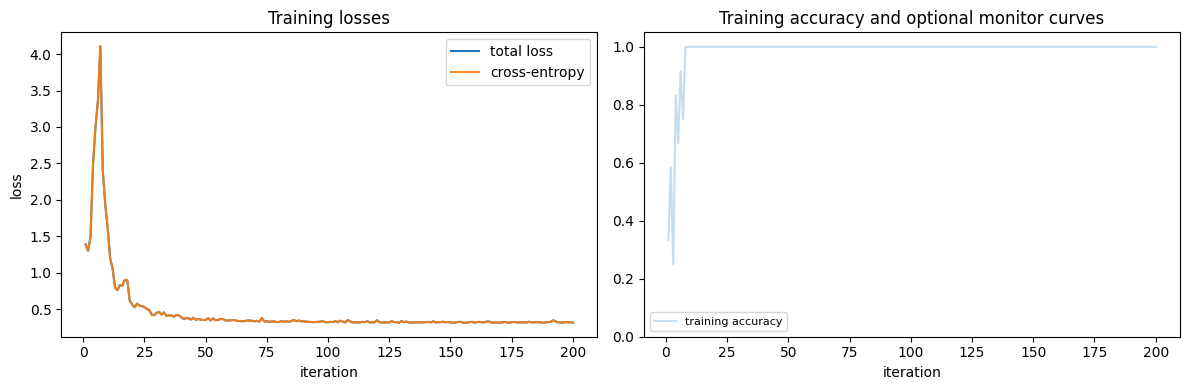


Final evaluation on the complete TEST_SET ...
Confusion matrix (rows=true, columns=predicted; order: negative, neutral, positive)
[[ 37  43 124]
 [  5  33  88]
 [ 31  69 319]]

Accuracy       : 51.936%
Macro precision: 44.506%
Macro recall   : 40.154%
Macro F1       : 39.409%
Weighted F1    : 48.942%

Per-class metrics:
  negative  precision=0.507 recall=0.181 f1=0.267
  neutral   precision=0.228 recall=0.262 f1=0.244
  positive  precision=0.601 recall=0.761 f1=0.672

Paper-style sensitivity (positive-class recall): 76.134%
Paper-style specificity (negative-class recall): 18.137%

Paper Table 2 reference for this model (accuracy, sensitivity, specificity):
  ScoNet: 51.3%, 100.0%, 33.2%
  These are paper-reported references, not values computed from this run. The paper's metric reporting does not perfectly reconcile with its published three-class confusion matrix, so compare cautiously.


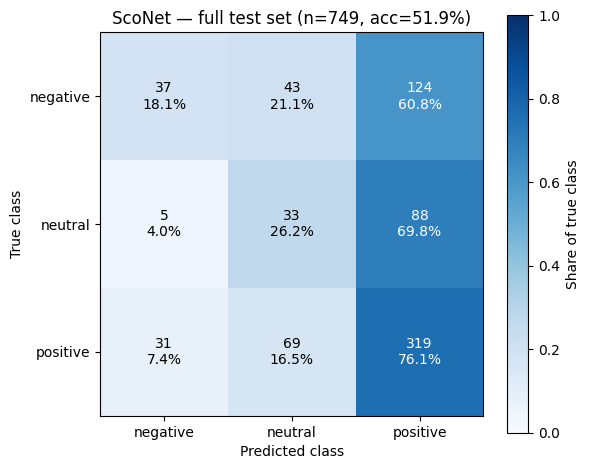


Paper reference accuracy for split 118, ScoNet: 51.3% (reported after 20,000 iterations; reference only)


In [11]:
if not RUN_FULL:
    print("Full training skipped. Verify the paths and class counts, then set RUN_FULL=True.")
else:
    partition = load_partition(PARTITION_JSON)
    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])
    check_split(train_items, test_items, partition)

    if ONE_PER_CLASS:
        print("WARNING: ONE_PER_CLASS=True is a toy experiment, not a reproduction.")
        train_items = select_one_per_class(train_items)

    selected_subjects = {sid for sid, _, _ in train_items}
    if len(selected_subjects) < 2 and TRIPLET_MODE[MODEL_VARIANT] is not None:
        raise ValueError("Triplet training requires at least two subjects in the training split.")

    actual_batch_ids = min(IDENTITIES_PER_BATCH, len(selected_subjects))
    if actual_batch_ids != IDENTITIES_PER_BATCH:
        print(f"WARNING: requested {IDENTITIES_PER_BATCH} subjects per batch, but only {actual_batch_ids} are available.")

    if DEVICE.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        print(f"GPU: {torch.cuda.get_device_name(0)} | VRAM: {props.total_memory / 1e9:.1f} GB | AMP: {USE_AMP}")

    print(f"\nModel objective: {MODEL_VARIANT} | triplet mode: {TRIPLET_MODE[MODEL_VARIANT]}")
    print(f"Train sequences: {len(train_items)} | test sequences: {len(test_items)}")
    print(f"Batch: {actual_batch_ids} identities x {SEQUENCES_PER_IDENTITY} sequences")
    print(f"Iterations: {TOTAL_ITERS:,} | LR milestones: {LR_MILESTONES}")

    if MONITOR_DURING_TRAINING:
        monitor_items = make_monitor_subset(test_items)
        monitor_every = MONITOR_EVERY
        print("Monitoring a fixed, class-balanced subset of TEST_SET; it is not used for gradients.")
    else:
        monitor_items = None
        monitor_every = 0

    set_seed()
    experiment_model = make_model()
    batch_fn = make_triplet_batch_fn(
        train_items, IDENTITIES_PER_BATCH, SEQUENCES_PER_IDENTITY
    )
    checkpoint_path = Path("checkpoints") / f"sconet_{MODEL_VARIANT}_{SPLIT_KEY}_{PROFILE}.pt"

    history = train(
        experiment_model,
        batch_fn,
        TOTAL_ITERS,
        triplet_mode=TRIPLET_MODE[MODEL_VARIANT],
        lr=BASE_LR,
        milestones=LR_MILESTONES,
        log_every=LOG_EVERY,
        amp=USE_AMP,
        checkpoint_path=checkpoint_path,
        save_every=SAVE_EVERY,
        resume=RESUME,
        monitor_items=monitor_items,
        monitor_every=monitor_every,
    )

    plot_training_history(history, TRIPLET_MODE[MODEL_VARIANT])

    print("\nFinal evaluation on the complete TEST_SET ...")
    test_confusion = confusion_matrix_for_items(experiment_model, test_items)
    final_metrics = report_metrics(test_confusion)
    plot_confusion_matrix(test_confusion, f"{MODEL_VARIANT} — full test set")

    if SPLIT_KEY in PAPER_ACCURACY and MODEL_VARIANT in PAPER_ACCURACY[SPLIT_KEY]:
        print(f"\nPaper reference accuracy for split {SPLIT_KEY}, {MODEL_VARIANT}: "
              f"{PAPER_ACCURACY[SPLIT_KEY][MODEL_VARIANT]:.1f}% "
              f"(reported after 20,000 iterations; reference only)")